# 03 - Análise exploratória dos dados




## 1. Objetivo do notebook

Este notebook tem como objetivo investigar o comportamento da série diária de precipitação da estação A701 do INMET entre 2010 e 2025.

A análise exploratória busca compreender a distribuição da chuva, a frequência de dias secos e chuvosos, a sazonalidade, a variabilidade ao longo do tempo, a ocorrência de eventos intensos e a relação com as variáveis meteorológicas auxiliares.

Os resultados desta etapa servirão de base para a definição das características temporais e meteorológicas que serão utilizadas posteriormente nos modelos preditivos.

## 2. Carregamento e validação da base diária

A análise parte da base consolidada na camada Gold, produzida após as etapas de controle de qualidade e agregação temporal realizadas no notebook anterior.

Antes da exploração estatística, são verificadas a quantidade de registros, o intervalo temporal e a estrutura das variáveis disponíveis.

In [3]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

arquivo_gold = Path("../data/gold/a701_2010_2025_diario.parquet")

df = pd.read_parquet(arquivo_gold)

df.head()

,DATA (YYYY-MM-DD),horas_validas,precipitacao_diaria_mm,dia_completo,temperatura_media,temperatura_media_horas_validas,umidade_media,umidade_media_horas_validas,pressao_media,pressao_media_horas_validas,vento_medio,vento_medio_horas_validas
0,2010-01-01,24,6.8,True,21.333333,24,86.916667,24,923.025000,24,2.329167,24
1,2010-01-02,24,36.2,True,22.166667,24,83.833333,24,925.041667,24,1.079167,24
2,2010-01-03,24,0.8,True,24.229167,24,78.625000,24,926.712500,24,1.433333,24
3,2010-01-04,24,13.4,True,24.241667,24,74.500000,24,926.695833,24,2.004167,24
4,2010-01-05,24,20.8,True,24.845833,24,72.666667,24,924.004167,24,1.762500,24


In [4]:
print("Linhas:", len(df))
print("Data mínima:", df["DATA (YYYY-MM-DD)"].min())
print("Data máxima:", df["DATA (YYYY-MM-DD)"].max())

df.info()

Linhas: 5844
Data mínima: 2010-01-01 00:00:00
Data máxima: 2025-12-31 00:00:00
<class 'pandas.DataFrame'>
RangeIndex: 5844 entries, 0 to 5843
Data columns (total 12 columns):
 #   Column                           Non-Null Count  Dtype         
---  ------                           --------------  -----         
 0   DATA (YYYY-MM-DD)                5844 non-null   datetime64[us]
 1   horas_validas                    5844 non-null   int64         
 2   precipitacao_diaria_mm           5655 non-null   float64       
 3   dia_completo                     5844 non-null   bool          
 4   temperatura_media                5802 non-null   float64       
 5   temperatura_media_horas_validas  5844 non-null   int64         
 6   umidade_media                    5809 non-null   float64       
 7   umidade_media_horas_validas      5844 non-null   int64         
 8   pressao_media                    5809 non-null   float64       
 9   pressao_media_horas_validas      5844 non-null   int64       

### Validação da base

A base diária contém 5.844 registros entre 1º de janeiro de 2010 e 31 de dezembro de 2025.

A precipitação diária apresenta 5.655 observações válidas, enquanto 189 dias permanecem com valor ausente devido ao critério de completude definido no pré-processamento. Esses registros ausentes não são interpretados como dias sem chuva.

## 3. Caracterização da precipitação diária

A primeira etapa da análise busca compreender a distribuição da variável-alvo. Essa caracterização é importante porque propriedades como alta frequência de zeros, assimetria e presença de valores extremos podem influenciar tanto a escolha dos modelos quanto a interpretação das métricas de desempenho.

In [5]:
df["precipitacao_diaria_mm"].describe()

count    5655.000000
mean        4.354200
std        11.026697
min         0.000000
25%         0.000000
50%         0.000000
75%         2.400000
max       143.000000
Name: precipitacao_diaria_mm, dtype: float64

### Interpretação das estatísticas descritivas

A precipitação diária apresenta média de 4,35 mm e mediana igual a 0 mm. A diferença entre essas medidas indica que a distribuição não é simétrica e possui forte concentração de dias sem precipitação.

Além disso, 75% dos dias apresentam até 2,4 mm de chuva, enquanto o maior valor observado é de 143 mm, indicando a presença de poucos eventos com volumes muito superiores ao comportamento típico da série.

## 4. Frequência de dias secos e chuvosos

In [6]:
dias_validos = df["precipitacao_diaria_mm"].notna().sum()

dias_secos = (
    df["precipitacao_diaria_mm"] == 0
).sum()

percentual_dias_secos = (
    dias_secos / dias_validos * 100
)

print("Dias válidos:", dias_validos)
print("Dias com 0 mm:", dias_secos)
print(f"Percentual de dias com 0 mm: {percentual_dias_secos:.2f}%")

Dias válidos: 5655
Dias com 0 mm: 3259
Percentual de dias com 0 mm: 57.63%


In [7]:
dias_com_precipitacao = (
    df["precipitacao_diaria_mm"] > 0
).sum()

dias_chuvosos_1mm = (
    df["precipitacao_diaria_mm"] >= 1
).sum()

print("Dias com precipitação > 0 mm:", dias_com_precipitacao)
print(
    f"Percentual > 0 mm: "
    f"{dias_com_precipitacao / dias_validos * 100:.2f}%"
)

print("Dias com precipitação >= 1 mm:", dias_chuvosos_1mm)
print(
    f"Percentual >= 1 mm: "
    f"{dias_chuvosos_1mm / dias_validos * 100:.2f}%"
)

Dias com precipitação > 0 mm: 2396
Percentual > 0 mm: 42.37%
Dias com precipitação >= 1 mm: 1730
Percentual >= 1 mm: 30.59%


In [8]:
dias_chuva_fraca = (
    (df["precipitacao_diaria_mm"] > 0)
    & (df["precipitacao_diaria_mm"] < 1)
).sum()

percentual_chuva_fraca = (
    dias_chuva_fraca / dias_validos * 100
)

print("Dias com precipitação entre 0 e 1 mm:", dias_chuva_fraca)
print(f"Percentual: {percentual_chuva_fraca:.2f}%")

Dias com precipitação entre 0 e 1 mm: 666
Percentual: 11.78%


In [9]:
def classificar_chuva(valor):
    if pd.isna(valor):
        return "Indisponível"
    elif valor == 0:
        return "Sem precipitação"
    elif valor < 1:
        return "Precipitação < 1 mm"
    else:
        return "Dia chuvoso (>= 1 mm)"

df["categoria_chuva"] = (
    df["precipitacao_diaria_mm"]
    .apply(classificar_chuva)
)

In [13]:
resumo_categorias_validas = (
    df.loc[df["categoria_chuva"] != "Indisponível", "categoria_chuva"]
    .value_counts()
    .to_frame("dias")
)

resumo_categorias_validas["percentual"] = (
    resumo_categorias_validas["dias"] /
    resumo_categorias_validas["dias"].sum() * 100
).round(2)

resumo_categorias_validas

,dias,percentual
categoria_chuva,,
Sem precipitação,3259,57.63
Dia chuvoso (>= 1 mm),1730,30.59
Precipitação < 1 mm,666,11.78


### Interpretação

Considerando apenas os 5.655 dias com registros válidos de precipitação, 57,63% não apresentaram chuva, 11,78% registraram precipitação inferior a 1 mm e 30,59% foram classificados como dias chuvosos, com precipitação igual ou superior a 1 mm.

A predominância de dias sem precipitação mostra que a série apresenta forte concentração de valores iguais a zero, característica que deverá ser considerada posteriormente na avaliação dos modelos preditivos.

In [14]:
chuva_dias_chuvosos = df.loc[
    df["precipitacao_diaria_mm"] >= 1,
    "precipitacao_diaria_mm"
]

chuva_dias_chuvosos.describe()

count    1730.000000
mean       14.086243
std        16.155583
min         1.000000
25%         3.200000
50%         8.400000
75%        18.800000
max       143.000000
Name: precipitacao_diaria_mm, dtype: float64

### Intensidade da precipitação nos dias chuvosos

Considerando apenas os 1.730 dias classificados como chuvosos (precipitação ≥ 1 mm), a precipitação média diária foi de 14,09 mm, enquanto a mediana foi de 8,40 mm.

A diferença entre média e mediana indica uma distribuição assimétrica à direita, na qual a maior parte dos dias apresenta volumes relativamente moderados, enquanto um número menor de eventos registra valores elevados de precipitação.

Metade dos dias chuvosos apresentou até 8,4 mm, enquanto 75% registraram até 18,8 mm. O maior acumulado diário observado foi de 143 mm.

Esse comportamento indica que eventos de precipitação intensa, embora menos frequentes, podem exercer influência relevante sobre a avaliação dos modelos preditivos, especialmente em métricas sensíveis a erros elevados, como o RMSE.

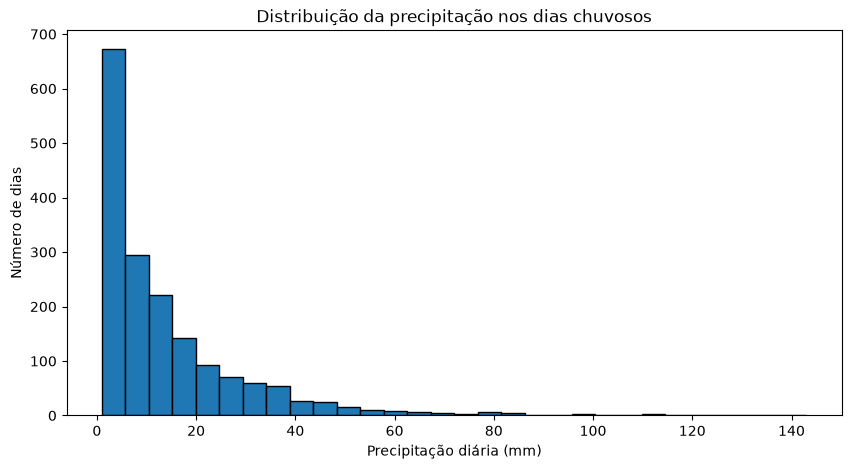

In [15]:
plt.figure(figsize=(10, 5))

plt.hist(
    chuva_dias_chuvosos,
    bins=30,
    edgecolor="black"
)

plt.title("Distribuição da precipitação nos dias chuvosos")
plt.xlabel("Precipitação diária (mm)")
plt.ylabel("Número de dias")

plt.show()

### Interpretação da distribuição

O histograma confirma a assimetria à direita da precipitação nos dias chuvosos. A maior parte dos registros está concentrada em baixos volumes de chuva, enquanto eventos mais intensos aparecem com frequência muito menor e formam uma cauda longa na distribuição.

Esse comportamento reforça que poucos eventos extremos elevam a média da precipitação e podem influenciar de forma importante métricas de erro mais sensíveis a grandes desvios, como o RMSE.

In [16]:
maiores_eventos = (
    df.loc[
        df["precipitacao_diaria_mm"].notna(),
        ["DATA (YYYY-MM-DD)", "precipitacao_diaria_mm"]
    ]
    .sort_values("precipitacao_diaria_mm", ascending=False)
    .head(10)
)

maiores_eventos

,DATA (YYYY-MM-DD),precipitacao_diaria_mm
3692,2020-02-10,143.0
5502,2025-01-24,125.4
2572,2017-01-16,120.8
3830,2020-06-27,113.6
423,2011-02-28,110.8
1078,2012-12-14,106.4
3643,2019-12-23,98.6
3256,2018-12-01,96.4
2653,2017-04-07,93.0
2184,2015-12-25,87.2


### Eventos de maior precipitação

Os maiores acumulados diários da série ocorreram de forma pontual ao longo do período analisado. O maior valor foi registrado em 10 de fevereiro de 2020, com 143,0 mm, seguido por 24 de janeiro de 2025, com 125,4 mm, e 16 de janeiro de 2017, com 120,8 mm.

Os dez maiores eventos apresentaram acumulados superiores a 87 mm. Esses valores ajudam a explicar a cauda longa observada na distribuição da precipitação e mostram que eventos de elevada intensidade são pouco frequentes, mas podem exercer influência importante sobre medidas estatísticas e sobre a avaliação dos modelos preditivos.

## 5. Sazonalidade da precipitação

A análise de sazonalidade busca verificar se o comportamento da precipitação apresenta padrões recorrentes ao longo dos meses do ano.

Essa etapa é importante porque a existência de diferenças sistemáticas entre os meses pode justificar posteriormente a criação de variáveis sazonais para os modelos preditivos, como mês do ano ou indicadores cíclicos

In [17]:
df["mes"] = df["DATA (YYYY-MM-DD)"].dt.month

In [18]:
precipitacao_media_mensal = (
    df.groupby("mes")["precipitacao_diaria_mm"]
    .mean()
    .round(2)
)

precipitacao_media_mensal

mes
1     9.51
2     9.12
3     6.31
4     2.87
5     1.58
6     2.36
7     1.31
8     1.19
9     2.15
10    4.20
11    4.59
12    6.89
Name: precipitacao_diaria_mm, dtype: float64

### Precipitação média diária por mês

A precipitação média diária apresenta diferenças expressivas ao longo do ano. Os maiores valores foram observados em janeiro (9,51 mm/dia), fevereiro (9,12 mm/dia) e dezembro (6,89 mm/dia), enquanto os menores ocorreram em julho (1,31 mm/dia) e agosto (1,19 mm/dia).

Esse comportamento indica a presença de sazonalidade na série. Entretanto, a precipitação média mensal pode ser influenciada tanto pela frequência de dias com chuva quanto pela intensidade dos eventos. Por esse motivo, essas duas características serão avaliadas separadamente nas etapas seguintes.

In [19]:
frequencia_chuva_mensal = (
    df.loc[df["precipitacao_diaria_mm"].notna()]
    .groupby("mes")
    .agg(
        dias_validos=("precipitacao_diaria_mm", "count"),
        dias_chuvosos=("precipitacao_diaria_mm", lambda x: (x >= 1).sum())
    )
)

frequencia_chuva_mensal["percentual_dias_chuvosos"] = (
    frequencia_chuva_mensal["dias_chuvosos"]
    / frequencia_chuva_mensal["dias_validos"]
    * 100
).round(2)

frequencia_chuva_mensal

,dias_validos,dias_chuvosos,percentual_dias_chuvosos
mes,,,
1,493,289,58.62
2,440,218,49.55
3,480,205,42.71
4,470,106,22.55
5,476,85,17.86
6,470,73,15.53
7,461,41,8.89
8,467,65,13.92
9,458,89,19.43


### Frequência de dias chuvosos por mês

A frequência de dias chuvosos apresentou forte variação ao longo do ano. Janeiro registrou a maior proporção, com 58,62% dos dias válidos apresentando precipitação igual ou superior a 1 mm, enquanto julho apresentou a menor frequência, com 8,89%.

Observa-se uma redução progressiva da frequência de dias chuvosos entre o verão e o inverno, seguida de aumento a partir da primavera.

Esse resultado reforça a existência de sazonalidade na série e mostra que as diferenças mensais de precipitação não estão relacionadas apenas à intensidade dos eventos, mas também à frequência com que a chuva ocorre.|

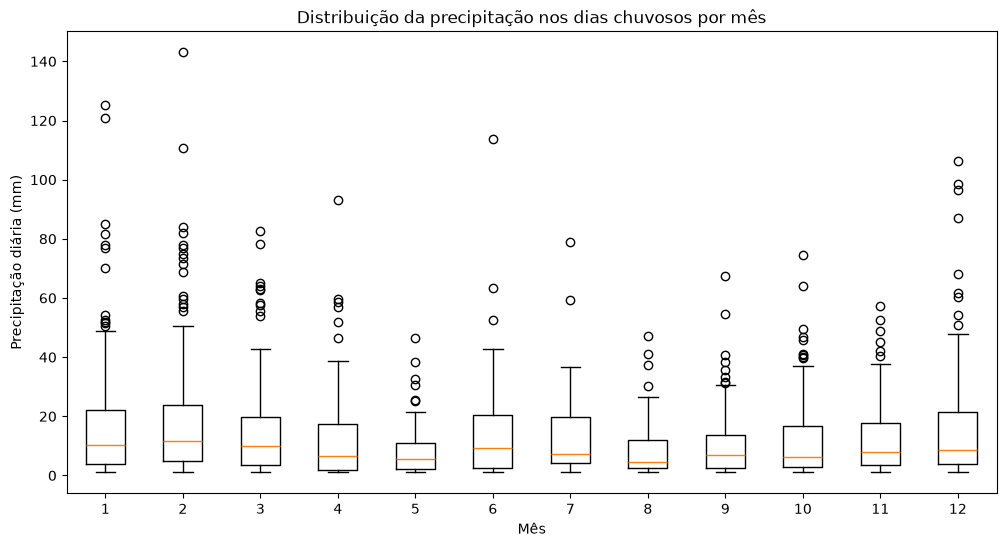

In [21]:
dados_boxplot = [
    df.loc[
        (df["mes"] == mes) &
        (df["precipitacao_diaria_mm"] >= 1),
        "precipitacao_diaria_mm"
    ]
    for mes in range(1, 13)
]

plt.figure(figsize=(12, 6))

plt.boxplot(
    dados_boxplot,
    label=[
        "Jan", "Fev", "Mar", "Abr", "Mai", "Jun",
        "Jul", "Ago", "Set", "Out", "Nov", "Dez"
    ],
    showfliers=True
)

plt.title("Distribuição da precipitação nos dias chuvosos por mês")
plt.xlabel("Mês")
plt.ylabel("Precipitação diária (mm)")

plt.show()

### Distribuição mensal da intensidade da precipitação

O boxplot mostra diferenças na distribuição da precipitação entre os meses, considerando apenas os dias classificados como chuvosos (≥ 1 mm).

Os meses do início e do final do ano apresentam, em geral, maiores medianas e maior dispersão dos volumes diários. Nos meses de menor frequência de chuva, as medianas tendem a ser menores, embora também sejam observados episódios isolados de precipitação intensa.

Os pontos localizados além dos limites das caixas representam valores atípicos em relação à distribuição de cada mês e não foram removidos da análise, pois correspondem a eventos meteorológicos observados na série.

Em conjunto com a análise da precipitação média e da frequência de dias chuvosos, esses resultados reforçam a presença de comportamento sazonal na série da estação A701.

## 6. Dependência temporal da precipitação

Esta etapa busca verificar se a precipitação diária apresenta relação com valores observados em dias anteriores.

A identificação de dependência temporal é importante para avaliar se informações passadas da própria série podem contribuir para a previsão, servindo posteriormente como justificativa para a criação de variáveis defasadas (`lags`) e médias móveis.

In [22]:
for lag in [1, 2, 3, 7, 14, 30]:
    correlacao = df["precipitacao_diaria_mm"].autocorr(lag=lag)
    print(f"Lag {lag:>2} dias: {correlacao:.3f}")

Lag  1 dias: 0.202
Lag  2 dias: 0.114
Lag  3 dias: 0.081
Lag  7 dias: 0.069
Lag 14 dias: 0.060
Lag 30 dias: 0.039


### Autocorrelação da precipitação

A autocorrelação apresentou maior valor no atraso de um dia (`lag 1`), com coeficiente de 0,202. Nos atrasos seguintes, a correlação diminuiu progressivamente, chegando a 0,039 em 30 dias.

Esse comportamento indica que existe alguma dependência temporal entre dias consecutivos, porém essa relação é relativamente fraca e perde intensidade rapidamente.

Os resultados sugerem que defasagens curtas, especialmente de 1 a 3 dias, podem ser avaliadas posteriormente na etapa de engenharia de atributos, enquanto lags mais longos apresentam menor evidência de relação direta com a precipitação diária.

<Figure size 1200x500 with 0 Axes>

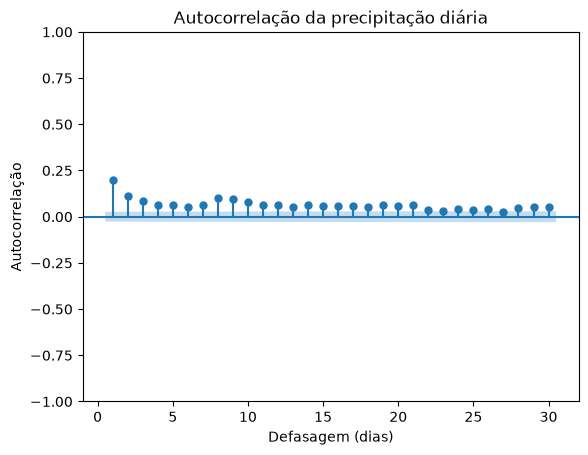

In [23]:
from statsmodels.graphics.tsaplots import plot_acf

serie_precipitacao = df["precipitacao_diaria_mm"].dropna()

plt.figure(figsize=(12, 5))

plot_acf(
    serie_precipitacao,
    lags=30,
    zero=False
)

plt.title("Autocorrelação da precipitação diária")
plt.xlabel("Defasagem (dias)")
plt.ylabel("Autocorrelação")

plt.show()

### Análise da autocorrelação

O gráfico de autocorrelação confirma que a maior dependência temporal ocorre no primeiro dia de defasagem, com correlação próxima de 0,20.

Nos lags seguintes, os coeficientes permanecem positivos, porém com magnitudes menores. Embora vários atrasos apresentem autocorrelação estatisticamente diferente de zero, os valores observados são baixos, indicando dependência temporal limitada.

Esse resultado sugere que defasagens curtas, principalmente de 1 a 3 dias, podem ser testadas posteriormente na etapa de engenharia de atributos. A utilidade dessas variáveis será confirmada pela comparação do desempenho dos modelos, e não apenas pela magnitude da correlação.

## 7. Relação entre precipitação e variáveis meteorológicas auxiliares

In [24]:
variaveis_correlacao = [
    "precipitacao_diaria_mm",
    "temperatura_media",
    "umidade_media",
    "pressao_media",
    "vento_medio"
]

correlacoes = (
    df[variaveis_correlacao]
    .corr()["precipitacao_diaria_mm"]
    .drop("precipitacao_diaria_mm")
    .sort_values(ascending=False)
)

correlacoes

umidade_media        0.339962
temperatura_media    0.077254
vento_medio         -0.070419
pressao_media       -0.260365
Name: precipitacao_diaria_mm, dtype: float64

### Correlação com as variáveis meteorológicas auxiliares

A umidade média apresentou a maior correlação linear positiva com a precipitação diária (0,34), indicando que maiores níveis de umidade tendem a estar associados a maiores volumes de chuva.

A pressão atmosférica apresentou correlação negativa de -0,26, sugerindo que menores valores de pressão tendem a ocorrer em dias com maior precipitação.

Temperatura média e velocidade média do vento apresentaram correlações próximas de zero, indicando baixa associação linear direta com a precipitação.

Esses resultados são utilizados apenas como uma análise exploratória inicial. Correlações lineares baixas não implicam necessariamente ausência de contribuição preditiva, especialmente em modelos capazes de representar relações não lineares e interações entre variáveis.

In [25]:
matriz_correlacao = df[
    [
        "precipitacao_diaria_mm",
        "temperatura_media",
        "umidade_media",
        "pressao_media",
        "vento_medio"
    ]
].corr().round(2)

matriz_correlacao

,precipitacao_diaria_mm,temperatura_media,umidade_media,pressao_media,vento_medio
precipitacao_diaria_mm,1.00,0.08,0.34,-0.26,-0.07
temperatura_media,0.08,1.00,-0.41,-0.60,-0.10
umidade_media,0.34,-0.41,1.00,0.03,0.11
pressao_media,-0.26,-0.60,0.03,1.00,-0.05
vento_medio,-0.07,-0.10,0.11,-0.05,1.00


### Matriz de correlação entre as variáveis

A matriz de correlação mostra que, entre as variáveis auxiliares, a relação linear mais intensa ocorre entre temperatura média e pressão média, com coeficiente de -0,60. Também se observa uma relação negativa moderada entre temperatura média e umidade média (-0,41).

As demais correlações entre variáveis auxiliares são baixas, especialmente aquelas envolvendo a velocidade média do vento.

Esses resultados indicam que existe alguma dependência entre determinadas variáveis meteorológicas, mas não há evidência de redundância extrema entre todo o conjunto. Dessa forma, todas as variáveis podem ser mantidas inicialmente para avaliação no cenário multivariado.

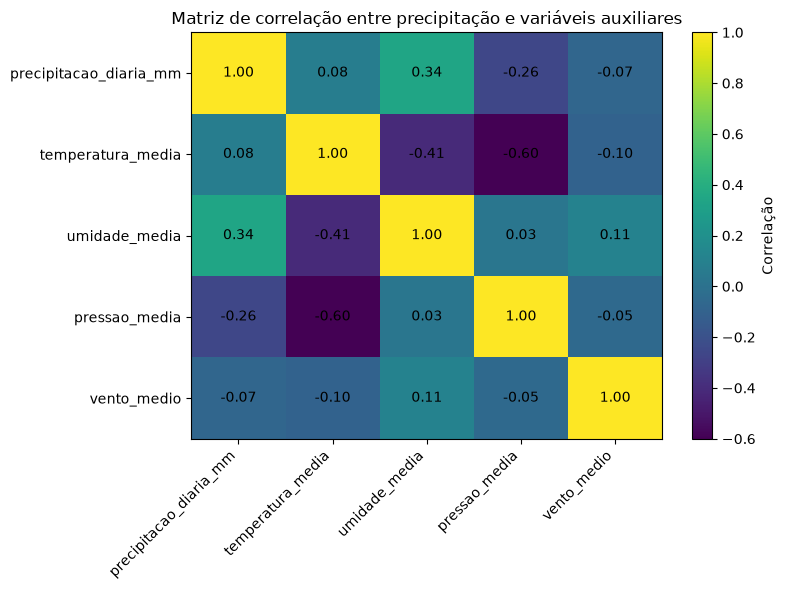

In [26]:
plt.figure(figsize=(8, 6))

plt.imshow(matriz_correlacao, aspect="auto")

plt.colorbar(label="Correlação")

plt.xticks(
    range(len(matriz_correlacao.columns)),
    matriz_correlacao.columns,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(matriz_correlacao.index)),
    matriz_correlacao.index
)

for i in range(len(matriz_correlacao.index)):
    for j in range(len(matriz_correlacao.columns)):
        plt.text(
            j, i,
            f"{matriz_correlacao.iloc[i, j]:.2f}",
            ha="center",
            va="center"
        )

plt.title("Matriz de correlação entre precipitação e variáveis auxiliares")
plt.tight_layout()
plt.show()

### Visualização da matriz de correlação

O mapa de calor facilita a identificação visual das relações lineares entre a precipitação diária e as variáveis meteorológicas auxiliares.

Observa-se que a umidade média apresenta a associação positiva mais evidente com a precipitação, enquanto a pressão média apresenta associação negativa. Entre as próprias variáveis auxiliares, destaca-se a correlação negativa entre temperatura média e pressão média, além da correlação negativa moderada entre temperatura média e umidade média.

De modo geral, as correlações observadas sugerem que as variáveis auxiliares carregam informações parcialmente complementares, justificando sua manutenção inicial para avaliação em modelos multivariados.